# Soft Computing

## Digitalna slika, OpenCV

### OpenCV

Open source biblioteka namenjena oblasti računarske vizije (eng. *computer vision*). Dokumentacija dostupna  [ovde](https://opencv.org/).

### Učitavanje slike

OpenCV metoda za učitavanje slike sa diska je <b>imread(path_to_image)</b>, koja kao parametar prima putanju do slike na disku. Učitana slika <i>img</i> je zapravo Numpy matrica, čije dimenzije zavise od same prirode slike. Ako je slika u boji, onda je <i>img</i> trodimenzionalna matrica, čije su prve dve dimenzije visina i širina slike, a treća dimenzija je veličine 3, zato što ona predstavlja boju (RGB, po jedan segment za svaku osnonvu boju).

In [3]:
import numpy as np
import cv2 # OpenCV biblioteka
import matplotlib
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [4]:
# iscrtavanje slika i grafika unutar samog browsera
%matplotlib inline 
# prikaz vecih slika 
matplotlib.rcParams['figure.figsize'] = 16,12

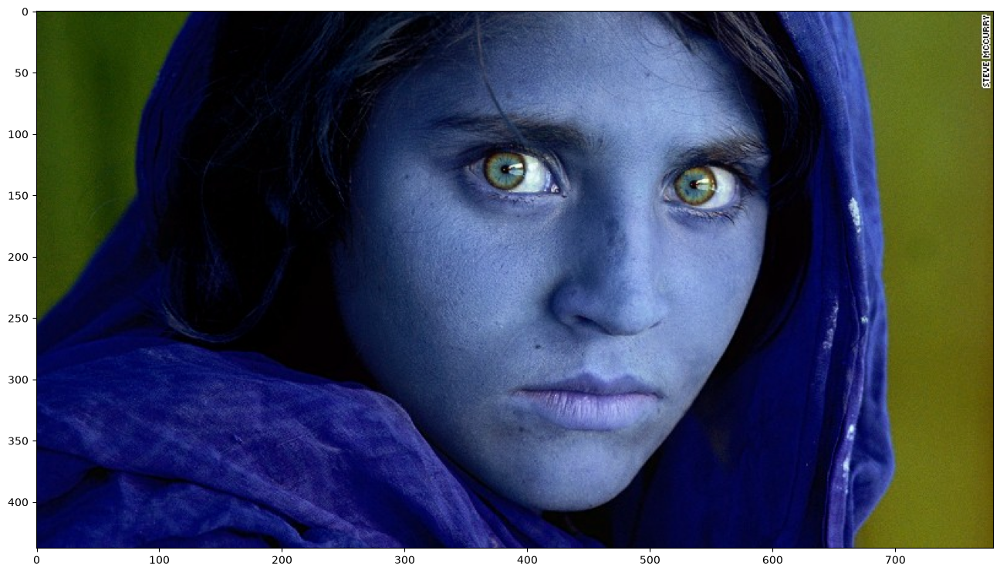

In [5]:
img = cv2.imread('images/girl.jpg') # ucitavanje slike sa diska
plt.imshow(img)  # prikazivanje slike

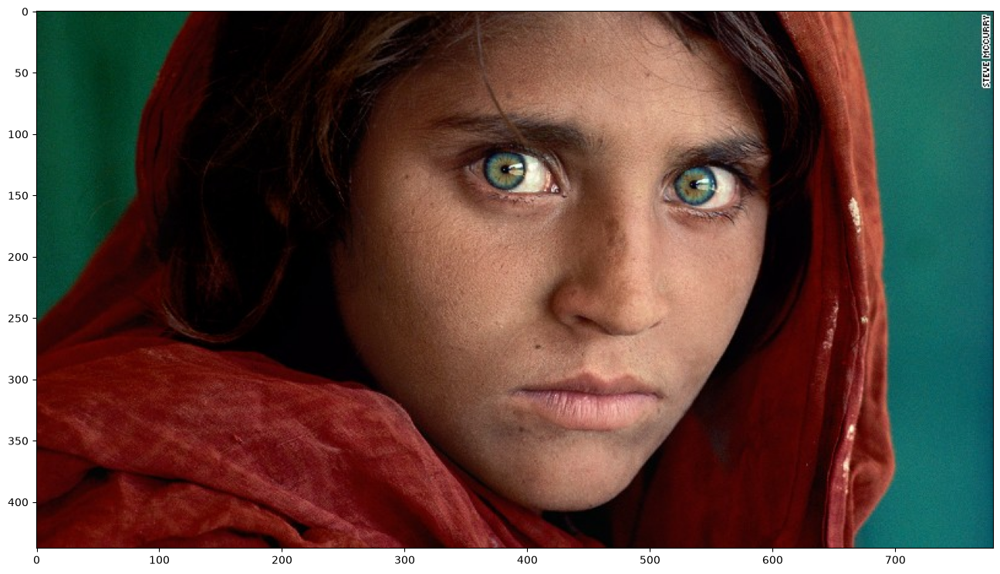

In [6]:
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # konvertovanje iz BGR u RGB model boja (OpenCV ucita sliku kao BGR)
plt.imshow(img)

### Prikazivanje dimenzija slike

In [7]:
print(img.shape)  # shape je property Numpy array-a za prikaz dimenzija
print("Visina slike: ", img.shape[0])
print("Sirina slike: ", img.shape[1])
print("Broj komponenti: ", img.shape[2])

(438, 780, 3)
Visina slike:  438
Sirina slike:  780
Broj komponenti:  3


Obratiti pažnju da slika u boji ima 3 komponente za svaki piksel na slici - R (red), G (green) i B (blue).
![images/cat_rgb.png](images/cat_rgb.png)

In [8]:
img

array([[[  8,  68,  40],
        [  9,  69,  41],
        [  7,  70,  41],
        ...,
        [ 28,  92,  91],
        [ 30, 100, 100],
        [ 28, 100,  99]],

       [[ 12,  71,  43],
        [ 10,  70,  42],
        [  9,  69,  41],
        ...,
        [ 40, 100, 100],
        [ 23,  91,  90],
        [ 26,  96,  94]],

       [[  4,  60,  33],
        [  9,  68,  40],
        [ 15,  74,  46],
        ...,
        [ 34,  89,  86],
        [ 31,  93,  90],
        [ 31, 100,  97]],

       ...,

       [[ 74,   6,   5],
        [ 73,   5,   4],
        [ 75,   4,   2],
        ...,
        [ 10,  94, 104],
        [  6,  93, 102],
        [  5,  92, 101]],

       [[ 76,   5,   3],
        [ 76,   5,   3],
        [ 79,   3,   3],
        ...,
        [ 11,  95, 106],
        [  7,  94, 104],
        [  4,  91, 101]],

       [[ 78,   4,   3],
        [ 78,   4,   3],
        [ 81,   3,   3],
        ...,
        [  7,  91, 102],
        [  4,  91, 101],
        [  2,  89,  99]]

Primetite da je svaki element matrice **uint8** (unsigned 8-bit integer), odnosno celobroja vrednost u intervalu [0, 255].

In [9]:
img.dtype

dtype('uint8')

### Osnovne operacije pomoću NumPy

Predstavljanje slike kao NumPy array je vrlo korisna stvar, jer omogućava jednostavnu manipulaciju i izvršavanje osnovih operacija nad slikom.

#### Isecanje (*crop*)

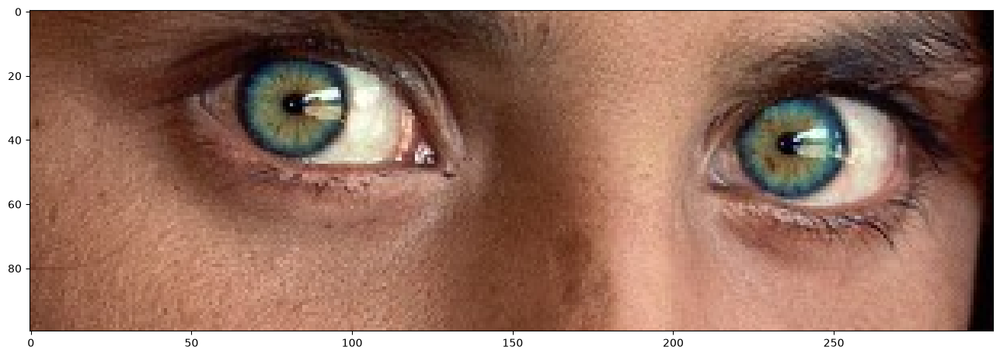

In [10]:
img_crop = img[100:200, 300:600]  # prva koordinata je po visini (formalno red), druga po širini (formalo kolona)
plt.imshow(img_crop) # "najmanja vrednost" koordinate visine se nalazi na vrhu, a najveca na dnu

#### Okretanje (*flip*)

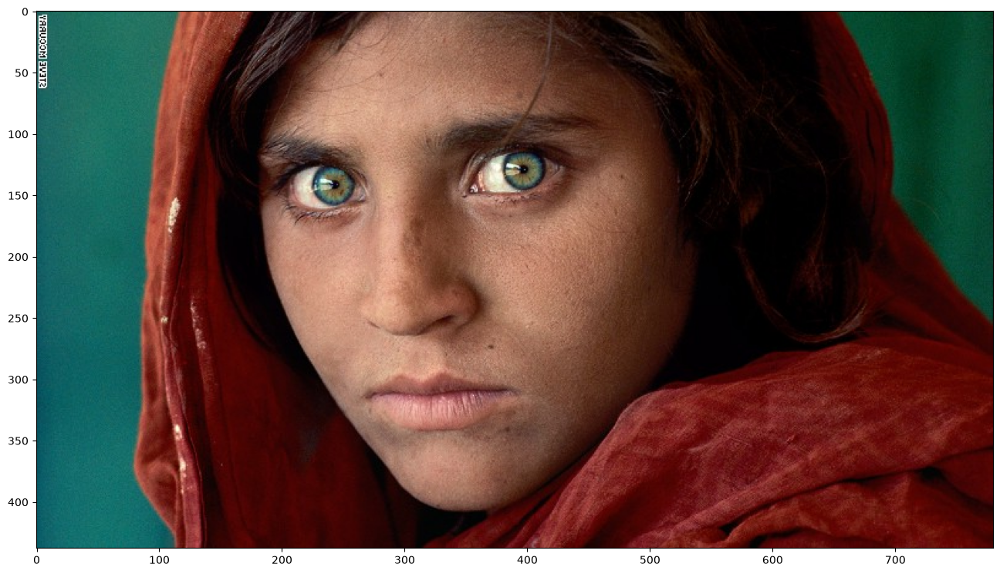

In [11]:
img_flip_h = img[:, ::-1]  # prva koordinata ostaje ista, a kolone se uzimaju unazad
plt.imshow(img_flip_h)

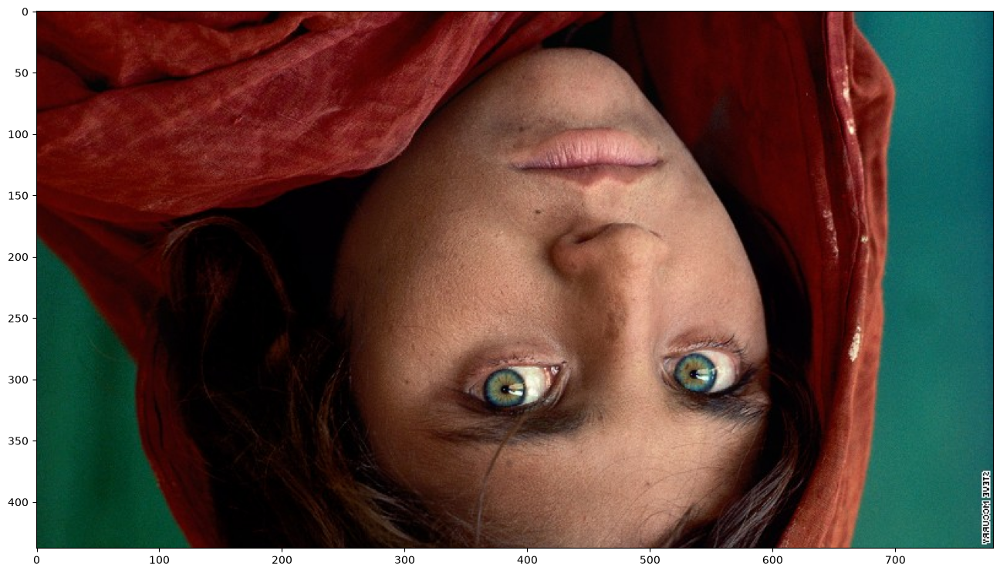

In [12]:
img_flip_v = img[::-1, :]  # druga koordinata ostaje ista, a redovi se uzimaju unazad
plt.imshow(img_flip_v)

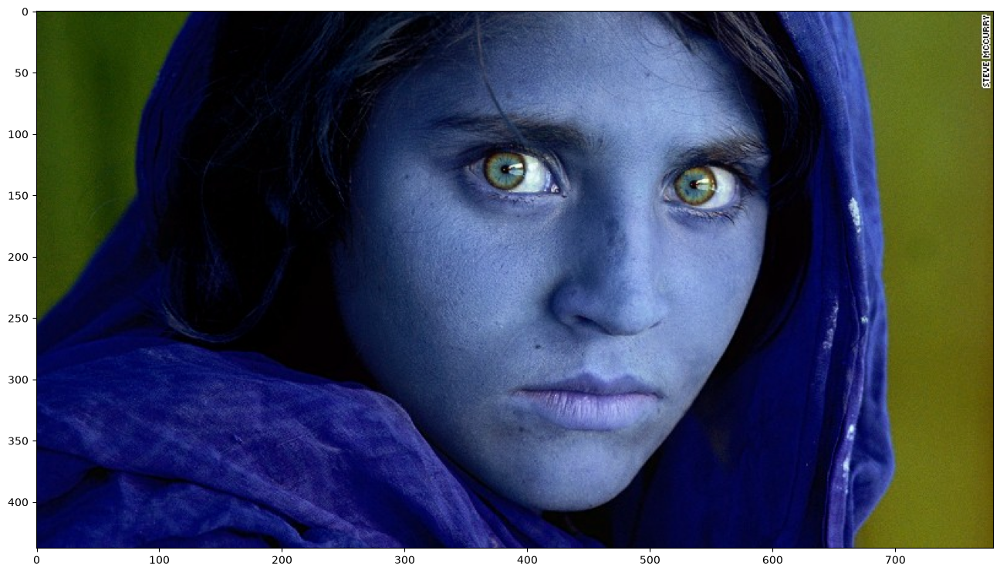

In [13]:
img_flip_c = img[:, :, ::-1]  # možemo i izmeniti redosled boja (RGB->BGR)
plt.imshow(img_flip_c)

#### Invertovanje

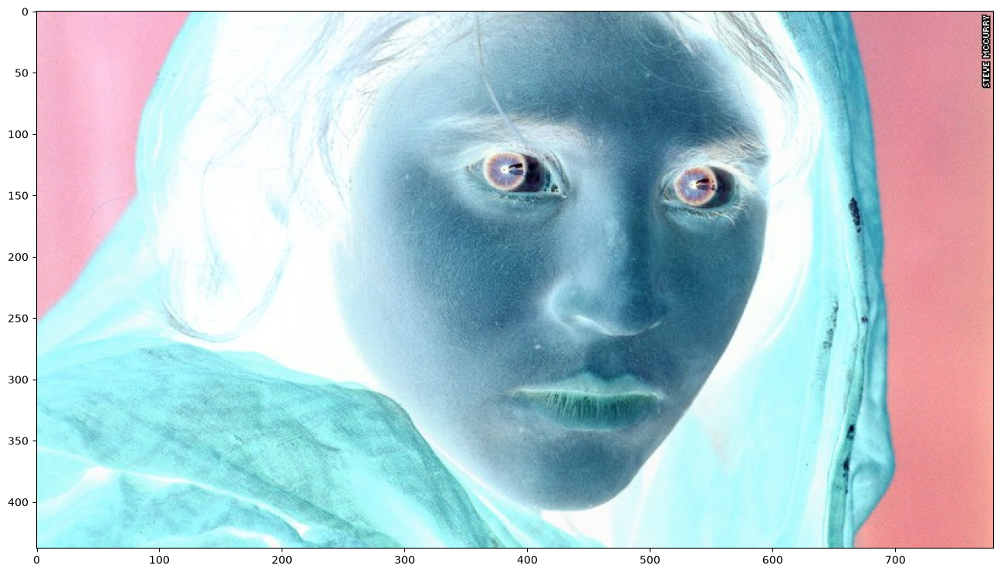

In [14]:
img_inv = 255 - img  # ako su pikeli u intervalu [0,255] ovo je ok, a ako su u intervalu [0.,1.] onda bi bilo 1. - img
plt.imshow(img_inv)

### Konvertovanje iz RGB u *grayscale*

Konvertovanjem iz RGB modela u nijanse sivih (grayscale) se gubi informacija o boji piksela na slici, ali sama slika postaje mnogo lakša za dalju obradu.

Ovo se može uraditi na više načina:
1. **Srednja vrednost** RGB komponenti - najjednostavnija varijanta $$ Y' = \frac{R+G+B}{3} $$
2. **Metod osvetljenosti** - srednja vrednost najjače i najslabije boje $$ Y' = \frac{max(R,G,B) + min(R,G,B)}{2} $$
3. **Metod perceptivne osvetljenosti** - težinska srednja vrednost koja uzima u obzir ljudsku percepciju (npr. najviše smo osetljivi na zelenu boju, pa to treba uzeti u obzir)$$ Y' = 0.21 \cdot R + 0.72 \cdot G + 0.07 \cdot B $$

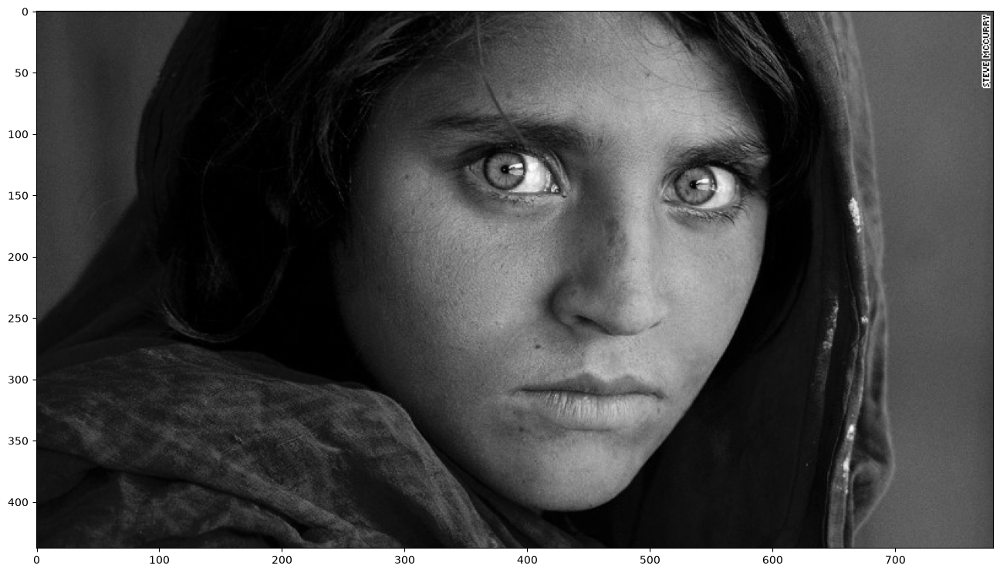

In [15]:
# implementacija metode perceptivne osvetljenosti
def my_rgb2gray(img_rgb):
    img_gray = np.ndarray((img_rgb.shape[0], img_rgb.shape[1]))  # zauzimanje memorije za sliku (nema trece dimenzije)
    img_gray = 0.21 * img_rgb[:, :, 0] + 0.72 * img_rgb[:, :, 1] + 0.07 * img_rgb[:, :, 2]
    img_gray = img_gray.astype('uint8')  # u prethodnom koraku smo mnozili sa float, pa sada moramo da vratimo u [0,255] opseg
    return img_gray

img_gray = my_rgb2gray(img)
plt.imshow(img_gray, 'gray') # kada se prikazuje slika koja nije RGB, obavezno je staviti 'gray' kao drugi parametar

Implementacija u OpenCV se oslanja na standard konverzije analognog u digitalni video format (*ITU-R BT.601*):
$$ Y' = 0.299 \cdot R + 0.587 \cdot G + 0.114 \cdot B $$
Razlika u odnosu na perceptivnu osvetljenost za realne fotografije se gotovo i ne primećuje.

In [16]:
img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

In [17]:
img_gray.shape

(438, 780)

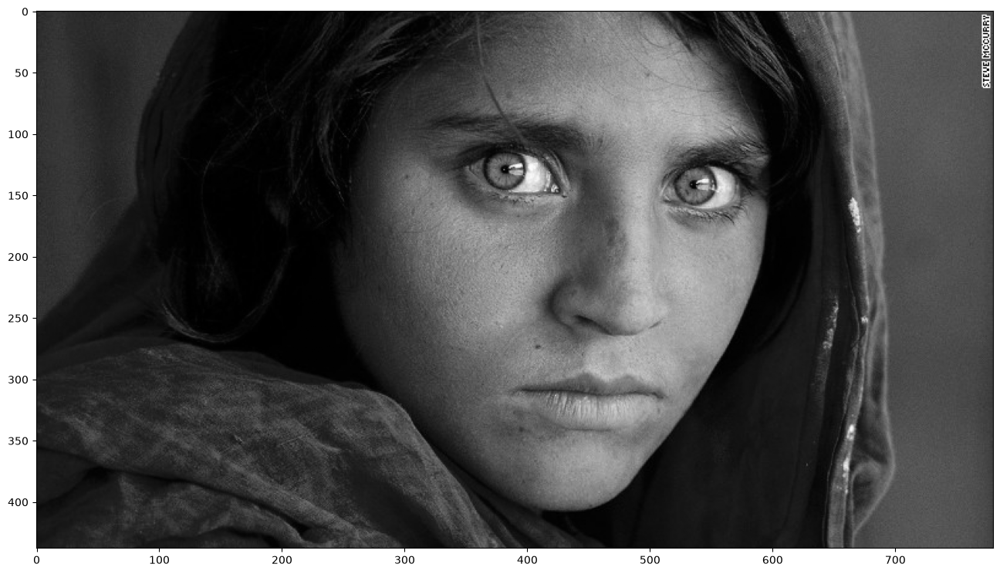

In [18]:
plt.imshow(img_gray, 'gray') 

In [19]:
print(img_gray.shape)
print("Visina slike: ", img_gray.shape[0])
print("Sirina slike: ", img_gray.shape[1])
print("Broj komponenti: 1")

(438, 780)
Visina slike:  438
Sirina slike:  780
Broj komponenti: 1


### Histogram

Histogram je grafički prikaz brojnosti piksela datog inteziteta. Daje nam informaciju o distribuciji osvetljenosti piksela.  

Pseudo-kod histograma za grayscale sliku:  
```code
inicijalizovati nula vektor od 256 elemenata  

za svaki piksel na slici:
    preuzeti inicijalni intezitet piksela
    uvecati za 1 broj piksela tog inteziteta

plotovati vektor
```

Koristeći **matplotlib**:

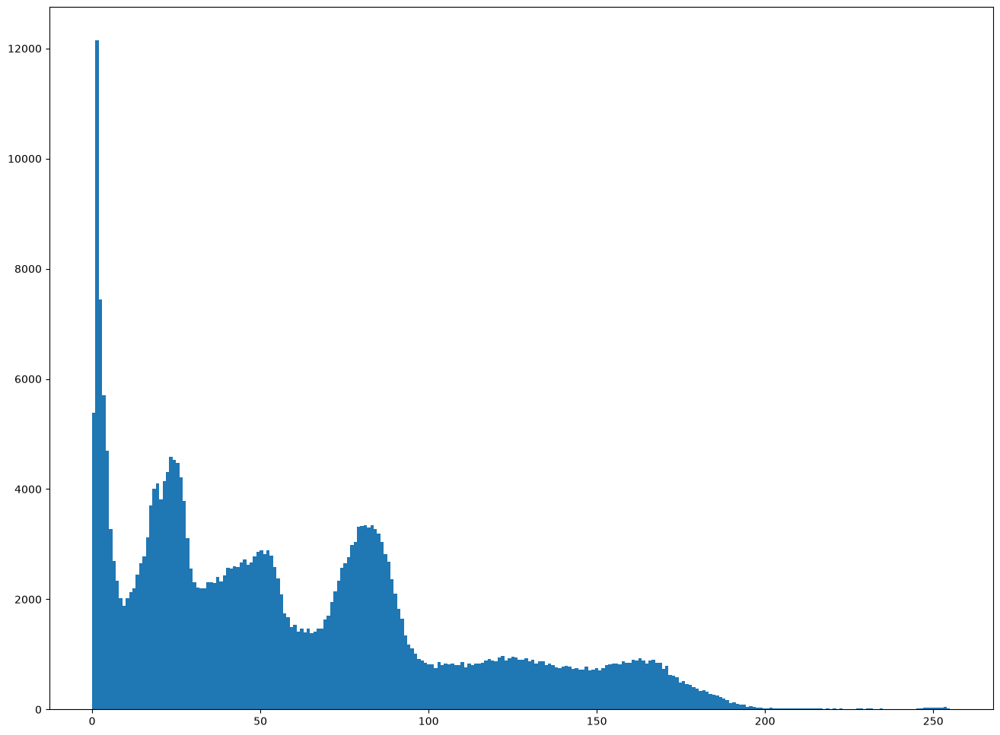

In [20]:
plt.hist(img_gray.ravel(), bins=256, range=(0, 255)) # .ravel() - prebacivanje visedimenzionalnog niza u jednodimenzionalni niz
plt.show()

Koristeći **OpenCV**:

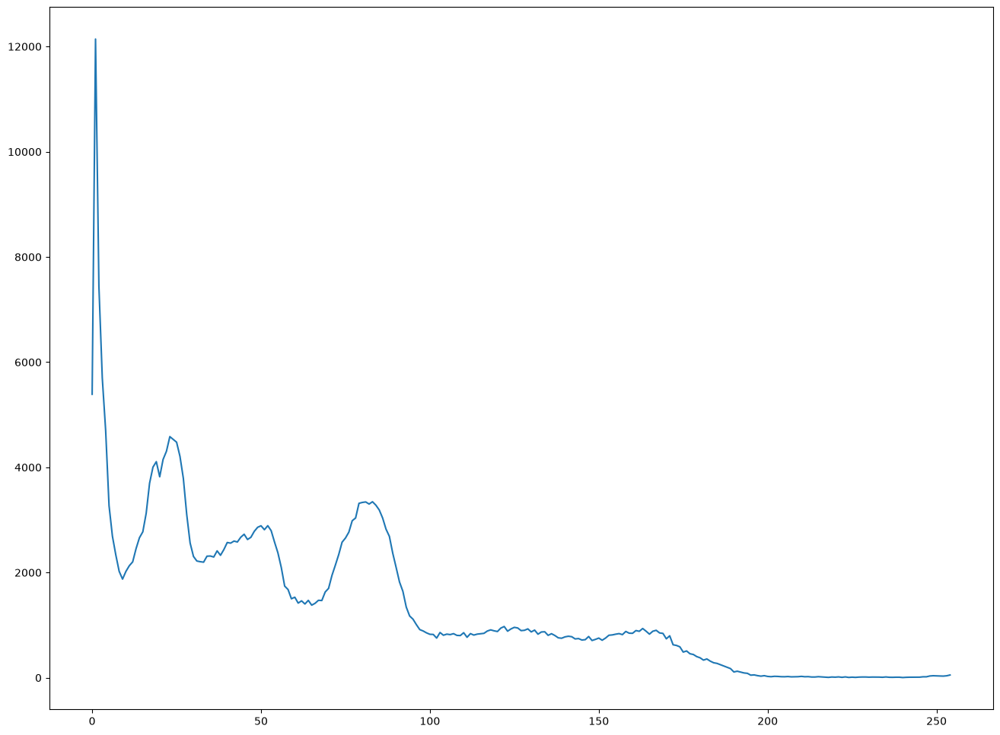

In [21]:
hist_full = cv2.calcHist([img_gray], [0], None, [255], [0, 255])
plt.plot(hist_full)
plt.show()

### Kontrast i osvetljenje slike

Kontrast i osvetljenje slike možemo podešavati pomoću metode [convertScaleAbs](https://docs.opencv.org/5.0/main_modules/core_array.html#convertscaleabs):

`adjusted = cv2.convertScaleAbs(image, alpha=alpha, beta=beta)`

Argumenti:
* <b>image</b> predstavlja učitanu sliku pomoću `cv2.imread` metode
* <b>alpha</b> predstavlja vrednost kontrasta. Ako želimo da <b>smanjimo</b> kontrast, koristićemo vrednosti 0 < alpha < 1, a ako želimo da ga <b>povećamo</b>, koristićemo vrednosti > 1
* <b>beta</b> predstavlja vrednost osvetljenja. Preporučljiv opseg vrednosti je između [-127, 127]

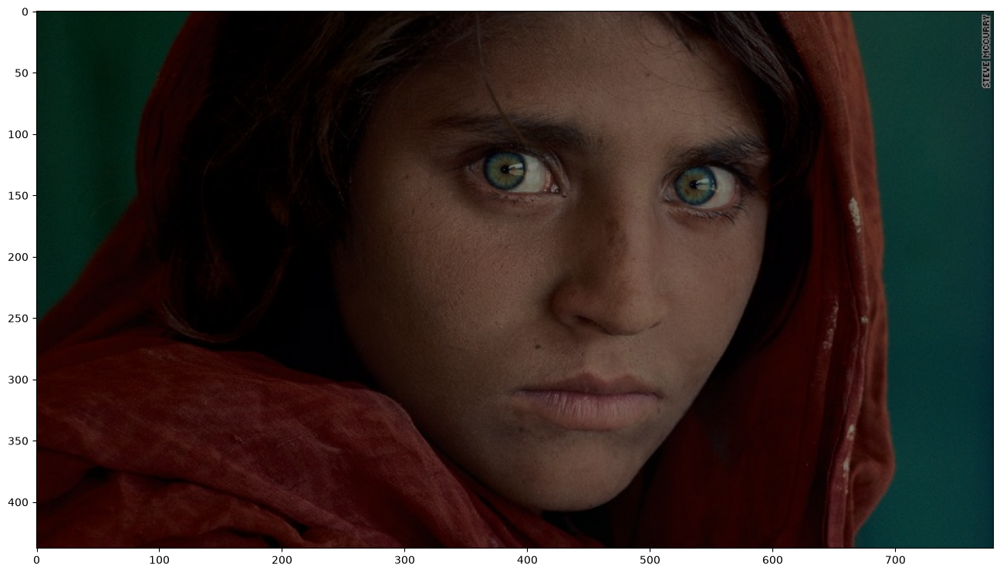

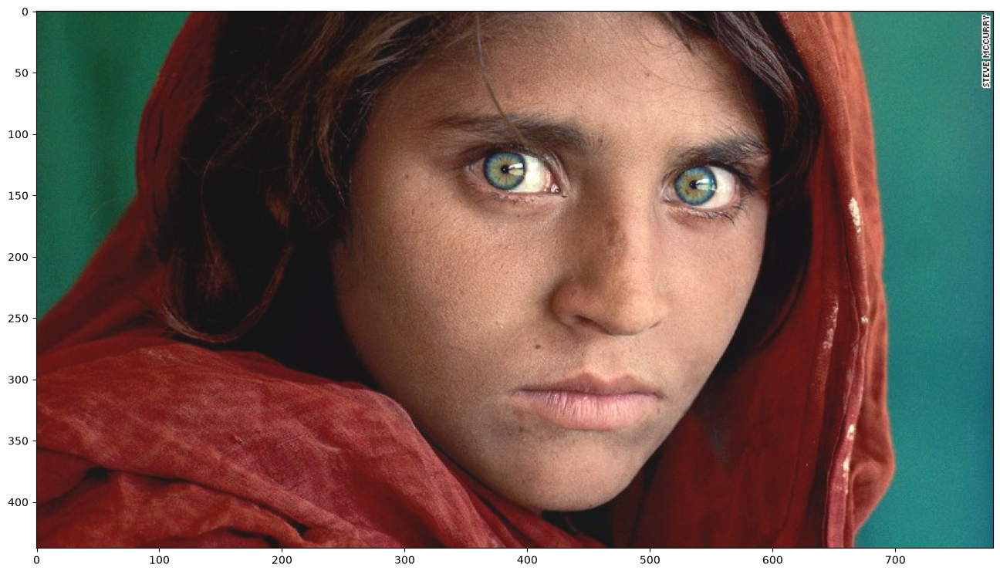

In [22]:
plt.figure() # ako je potrebno da se prikaze vise slika u jednoj celiji
img_lower_contrast = cv2.convertScaleAbs(img, alpha=0.5)
plt.imshow(img_lower_contrast)

plt.figure()
img_higher_brightness = cv2.convertScaleAbs(img, beta=20)
plt.imshow(img_higher_brightness)

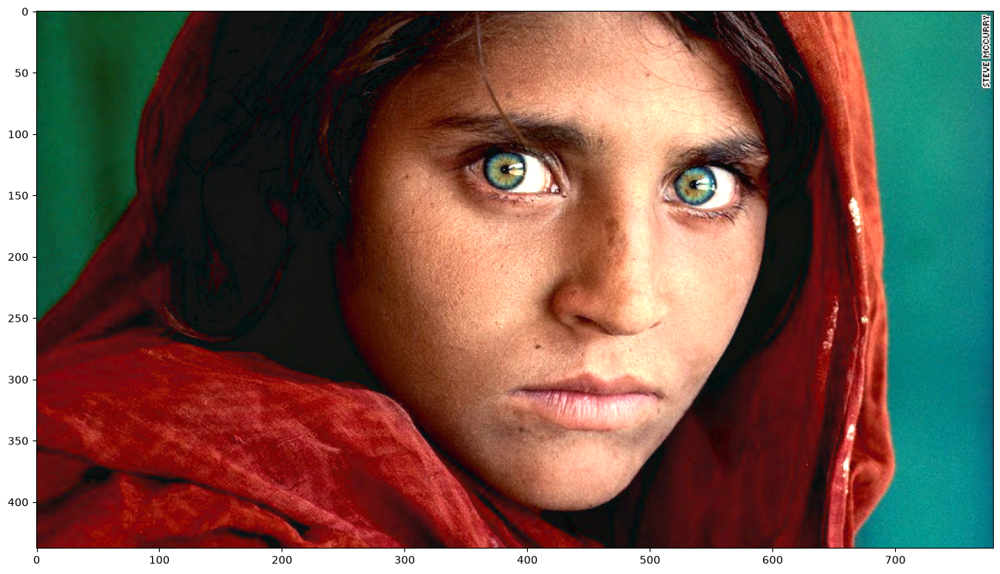

In [23]:
img_changed = cv2.convertScaleAbs(img, alpha=1.5, beta=-20)
plt.imshow(img_changed)

### Zamućenje (*blur* / *smoothing*)

Postupak uklanjanja visokih frekvencija sa slike, pre svega šuma i sitnih detalja. 

Zamućenje se realizuje prelaskom malog prozora zadatih dimenzija (*kernel*) preko slike. Dimenzije prozora su uvek neparni brojevi (npr. $3\times3$ ili $5\times5$) kako bi postojao tačno jedan centralni piksel koji se ažurira.

Najčešće korišćene [metode zamućenja u OpenCV-u](https://docs.opencv.org/5.0/py_tutorials/py_imgproc/py_filtering/py_filtering.html) su:

1. **Averaging** - vrednost piksela se zamenjuje običnim prosekom njegovog susedstva. Najbrži metod, ali stvara grube prelaze.

2. **Gaussian Blur** koristi normalnu (Gausovu) raspodelu gde pikseli bliži centru imaju veći uticaj. Standardan izbor za uklanjanje prirodnog šuma.

3. **Median Blur** - nelinearni filter koji uzima medijanu umesto proseka. Izuzetno efikasan za uklanjanje impulsnog (*salt & pepper*) šuma.

4. **Bilateral Filtering** - zamućuje homogene površine, ali prepoznaje i čuva oštre ivice. Daje vizuelno najlepše rezultate, ali je računski najsporiji.

Text(0.5, 1.0, 'Bilateral Filtering')

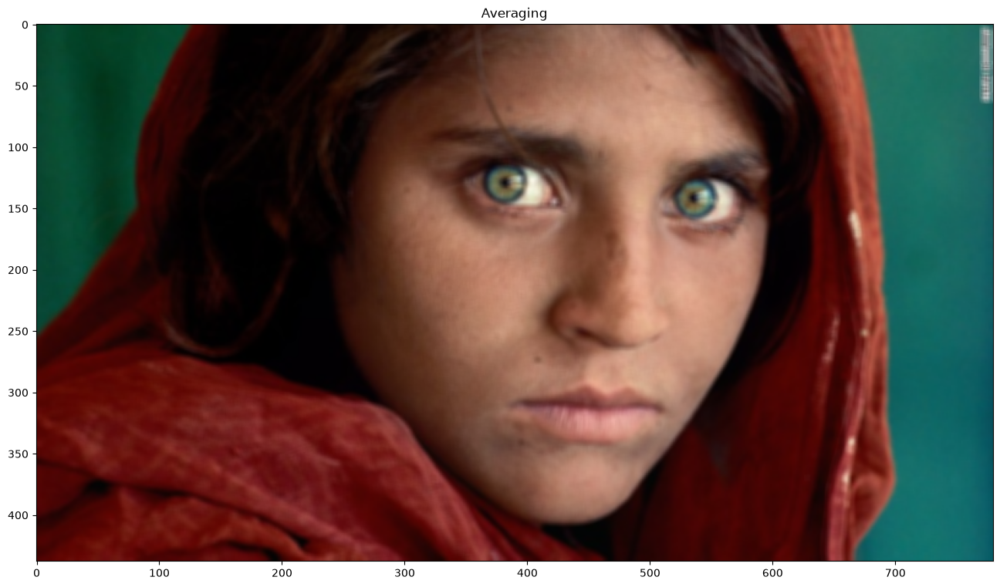

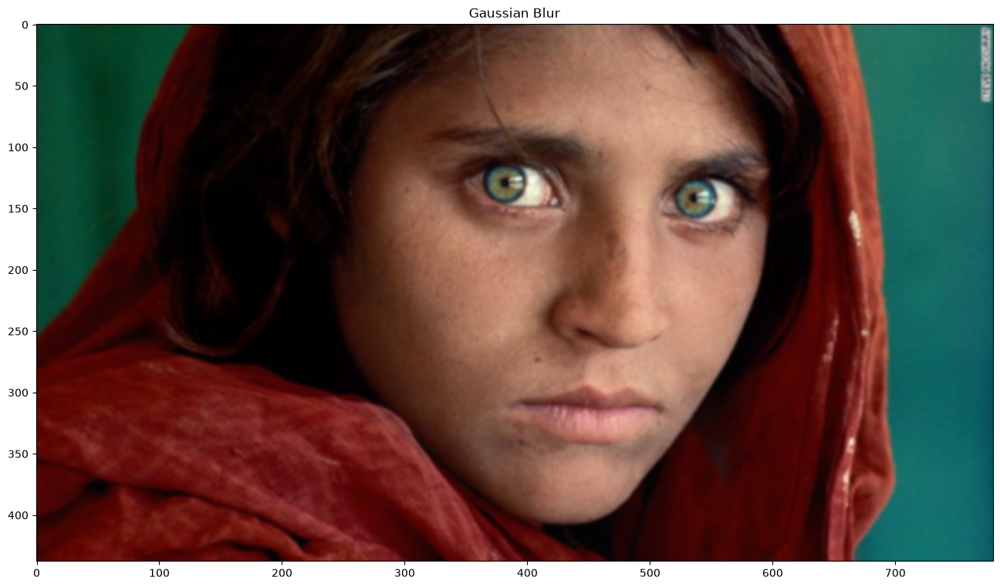

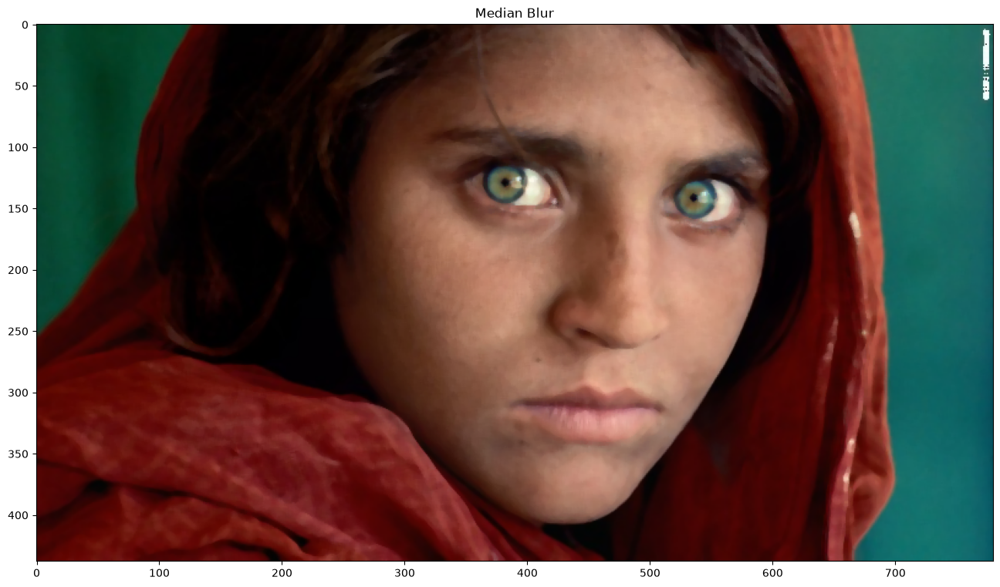

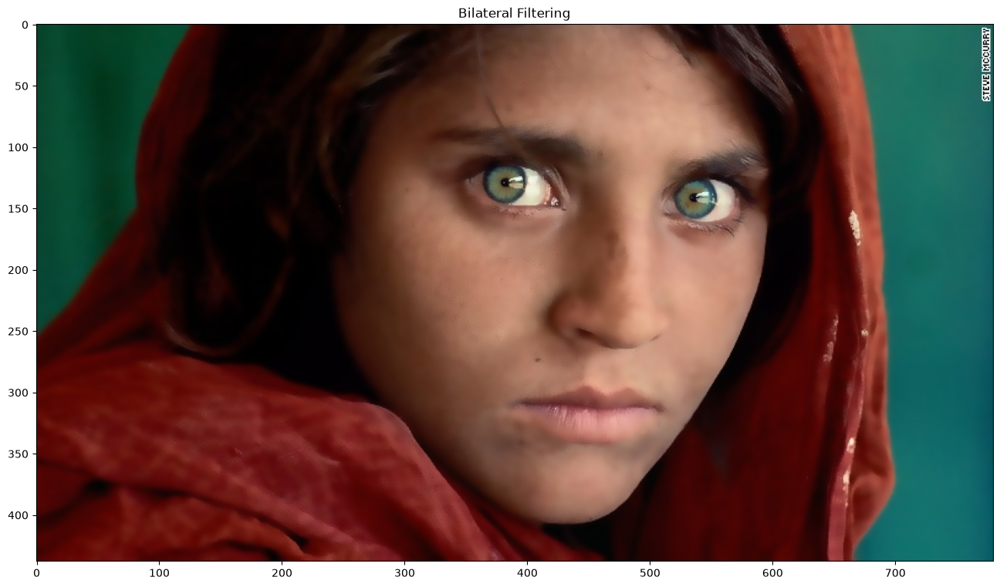

In [24]:
# 1. Averaging
plt.figure()
img_blur = cv2.blur(img, (5, 5))
plt.imshow(img_blur)
plt.title("Averaging")

# 2. Gaussian Blur
plt.figure()
img_gaussian = cv2.GaussianBlur(img, (5, 5), 0)
plt.imshow(img_gaussian)
plt.title("Gaussian Blur")

# 3. Median Blur 
plt.figure()
img_median = cv2.medianBlur(img, 5)
plt.imshow(img_median)
plt.title("Median Blur")

# 4. Bilateral Filtering
plt.figure()
img_bilateral = cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)
plt.imshow(img_bilateral)
plt.title("Bilateral Filtering")

### Binarna slika

Slika čiji pikseli imaju samo dve moguće vrednosti: crno i belo. U zavisnosti da li interval realan (`float32`) ili celobrojan (`uint8`), ove vrednosti mogu biti `{0,1}` ili `{0,255}`.

U binarnoj slici često izdvajamo ono što nam je bitno (**foreground**), od ono što nam je nebitno (**background**). Formalnije, ovaj postupak izdvajanja bitnog od nebitnog na slici nazivamo **segmentacija**.

Najčešći način dobijanja binarne slike je korišćenje nekog praga (**threshold**), pa ako je vrednost piksela veća od zadatog praga taj piksel dobija vrednost 1, u suprotnom 0. Postoji više tipova threshold-ovanja:

1. **Globalni threshold** - isti prag se primenjuje na sve piksele
2. **Lokalni threshold** - različiti pragovi za različite delove slike
3. **Adaptivni threshold** - prag se ne određuje ručno (ne zadaje ga čovek), već kroz neki postupak. Može biti i globalni i lokalni.

#### Globalni threshold

Kako izdvojiti, na primer, samo lice?

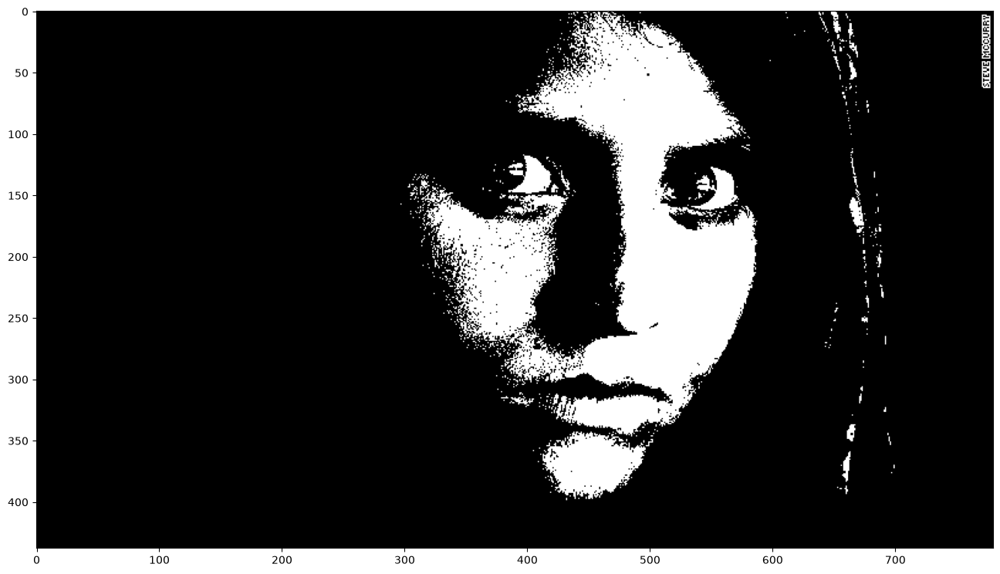

In [25]:
img_tr = img_gray > 127  # svi piskeli koji su veci od 127 ce dobiti vrednost True, tj. 1, i obrnuto
plt.imshow(img_tr, 'gray')

OpenCV ima metodu <b>threshold</b> koja:
* kao prvi parametar prima sliku koja se binarizuje
* kao drugi parametar prima prag binarizacije
* za treći parametar ima vrednost rezultujućeg piksela ako je veći od praga (255=belo)
* za poslednji parametar ima [tip thresholda](https://docs.opencv.org/5.0/main_modules/imgproc_misc.html#thresholdtypes) (u ovo slučaju je binarizacija).

100.0


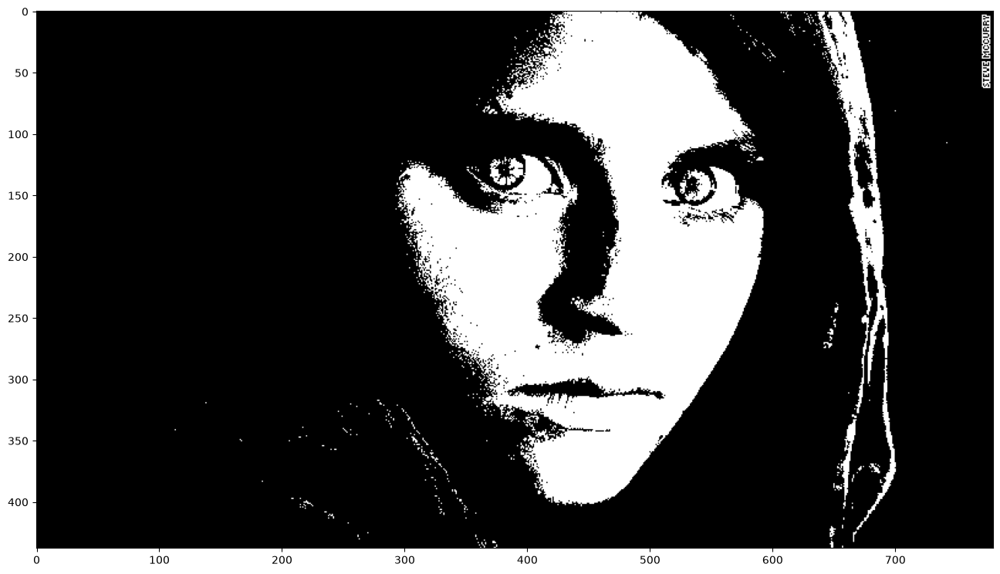

In [26]:
t, image_bin = cv2.threshold(img_gray, 100, 255, cv2.THRESH_BINARY) # t je vrednost praga, image_bin je binarna slika
print(t)
plt.imshow(image_bin, 'gray')

#### Otsu threshold

[Otsu metoda](https://en.wikipedia.org/wiki/Otsu%27s_method) se koristi za automatsko pronalaženje praga za threshold na slici. Prag se pronalazi na osnovu histograma.  

Ideja: optimalan prag je obično u "dolinama" histograma.

Otsu's threshold: 70.0


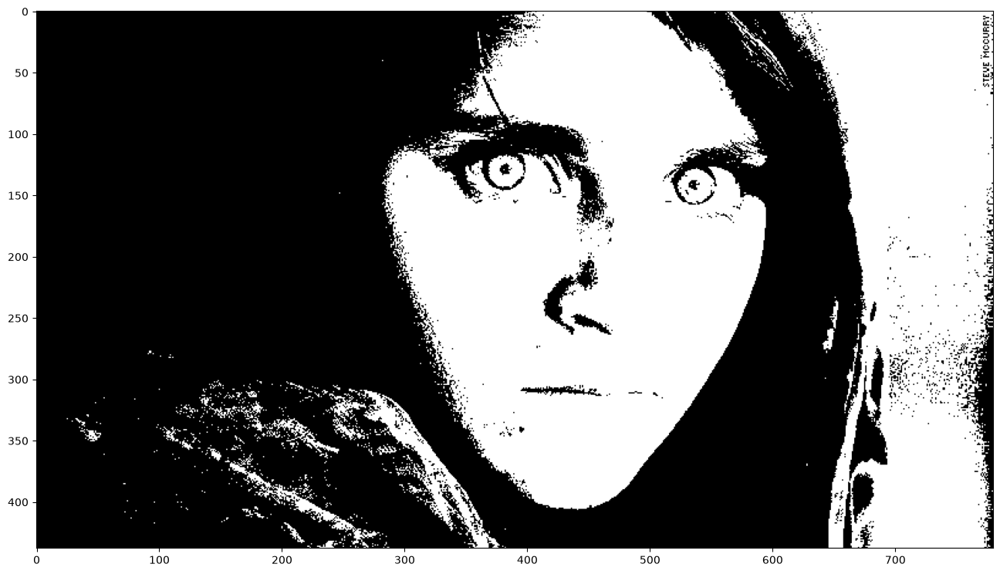

In [27]:
t, image_bin = cv2.threshold(img_gray, 0, 255, cv2.THRESH_OTSU) # t je izracunata vrednost praga, image_bin je binarna slika
print(f"Otsu's threshold: {t}")
plt.imshow(image_bin, 'gray')

#### Adaptivni threshold

U nekim slučajevima primena globalnog praga za threshold ne daje dobre rezultate. Dobar primer su slike na kojima se menja osvetljenje, gde globalni threshold praktično uništi deo slike koji je previše osvetljen ili zatamnjen.

Adaptivni threshold je drugačiji pristup, gde se za svaki piksel na slici izračunava zaseban prag, na osnovu njemu okolnih piksela.  

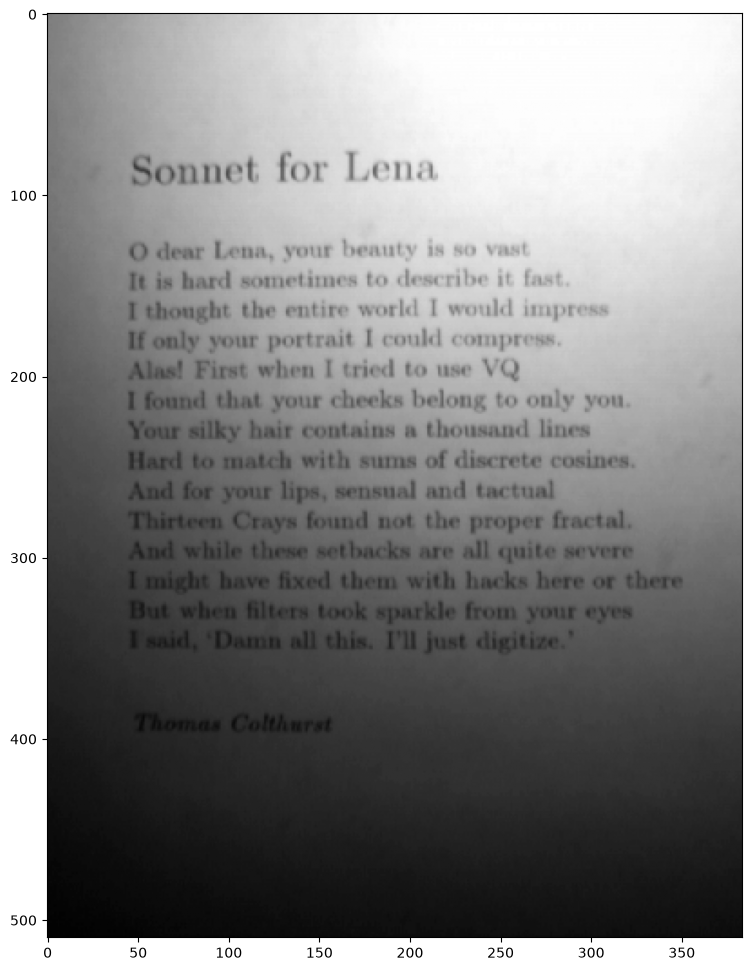

In [28]:
image_ada = cv2.imread('images/sonnet.png')
image_ada = cv2.cvtColor(image_ada, cv2.COLOR_BGR2GRAY)
plt.imshow(image_ada, 'gray')

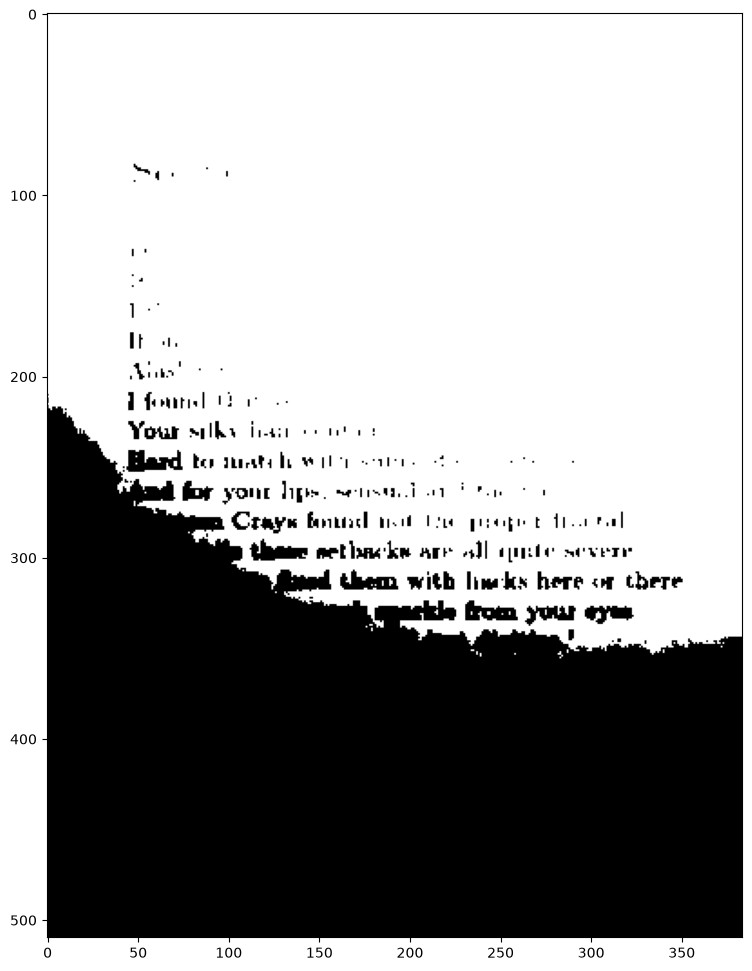

In [29]:
_, image_ada_bin = cv2.threshold(image_ada, 100, 255, cv2.THRESH_BINARY)
plt.imshow(image_ada_bin, 'gray')

Loši rezultati su dobijeni upotrebom globalnog thresholda.

Poboljšavamo rezultate korišćenjem adaptivnog thresholda. 

Pretposlednji parametar metode [adaptiveThreshold](https://docs.opencv.org/5.0/py_tutorials/py_imgproc/py_thresholding/py_thresholding.html) je ključan, jer predstavlja veličinu bloka susednih piksela (npr. 15x15) na osnovnu kojih se računa lokalni prag.

Poslednji parametar predstavlja konstantnu vrednost, koja se oduzima od (ponderisane) srednje vrednosti izračunate za susedne piksele jednog bloka. Formula: $$T(x, y) = mean(pikseliBloka) - C$$ gde nam C predstavlja prethodno spomenutu konstantu.

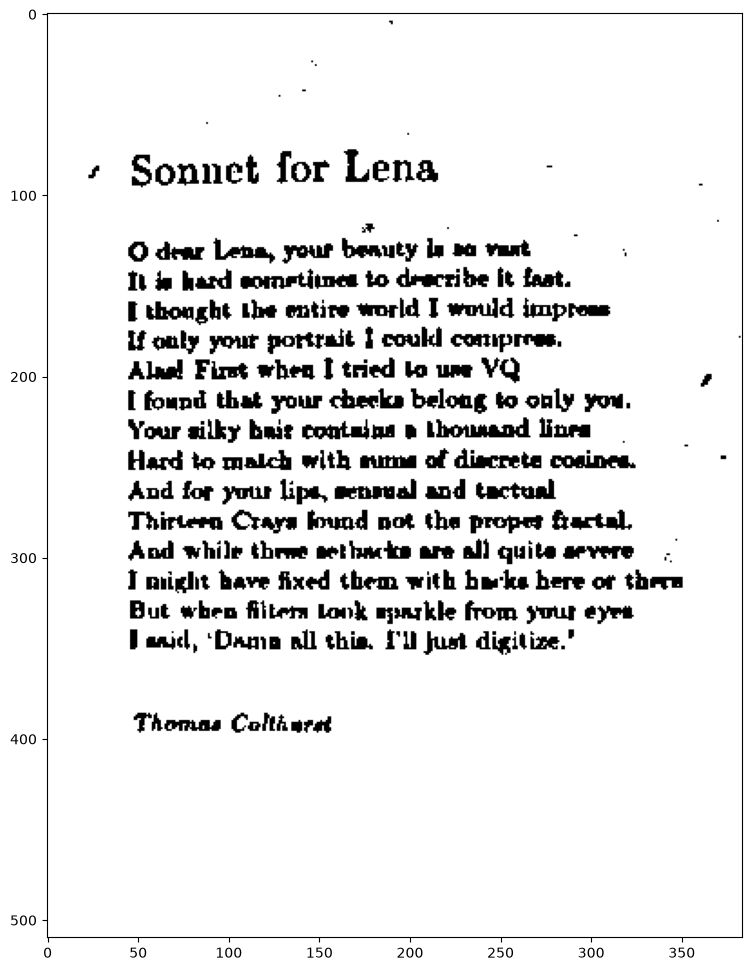

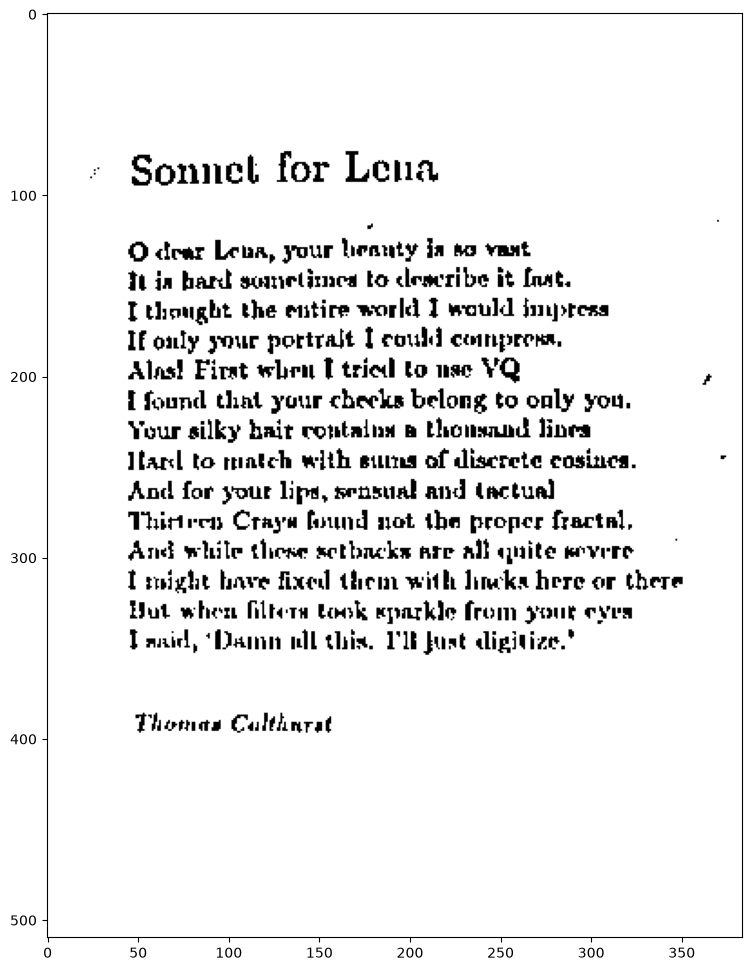

In [30]:
# adaptivni threshold gde se prag racuna = srednja vrednost okolnih piksela
image_ada_bin = cv2.adaptiveThreshold(image_ada, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 15, 5)
plt.figure() 
plt.imshow(image_ada_bin, 'gray')

# adaptivni threshold gde se prag racuna = tezinska suma okolnih piksela, gde su tezine iz gausove raspodele
image_ada_bin = cv2.adaptiveThreshold(image_ada, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 15, 5)
plt.figure()
plt.imshow(image_ada_bin, 'gray')

### HSV i maskiranje

Sve metode koje smo do sada radili rade nad *grayscale* slikom. Konverzija u *grayscale* je prvi korak, i već u njemu gubimo informaciju o boji. Ako nam je boja bitna, potreban nam je prostor boja u kojem je ona izdvojena kao posebna veličina.

**HSV** (*Hue*, *Saturation*, *Value*) razlaže boju na:
* **H** (nijansa) - koja boja je u pitanju
* **S** (zasićenje) - koliko je boja "čista": 0 je siva, 255 je potpuno zasićena boja
* **V** (svetlina) - koliko je svetla: 0 je crna, 255 je najsvetlije.

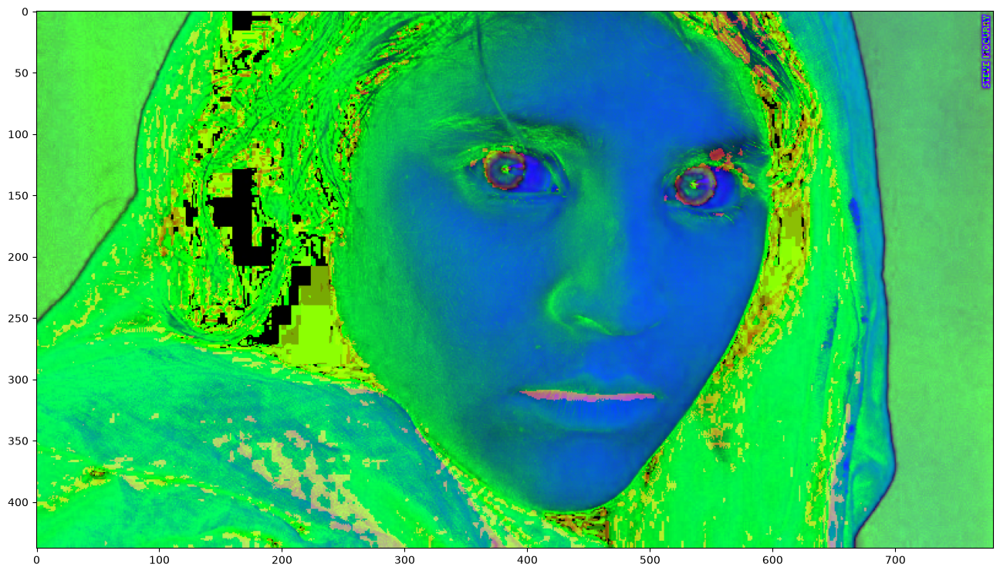

In [31]:
img_hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV) # konvertovanje iz RGB u HSV model boja
plt.imshow(img_hsv)

Iako HSV nije perceptivno ujednačen za ljudsko oko, izuzetno je praktičan za računarsku obradu.

Postupak maskiranja svodi se na:
1. Definisanje donje i gornje granice za željeni opseg boje
2. Pravljenje binarne maske sa [inRange](https://docs.opencv.org/5.0/main_modules/core_array.html#inrange) metodom
3. Primenu maske na originalnu sliku pomoću bitske operacije *AND*.

Text(0.5, 1.0, 'Izdvojena zelena boja')

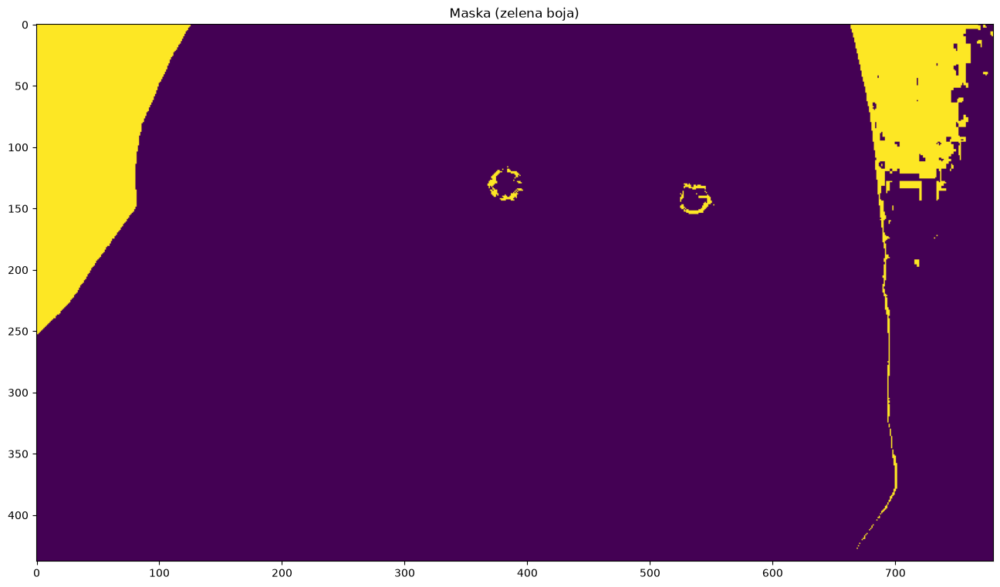

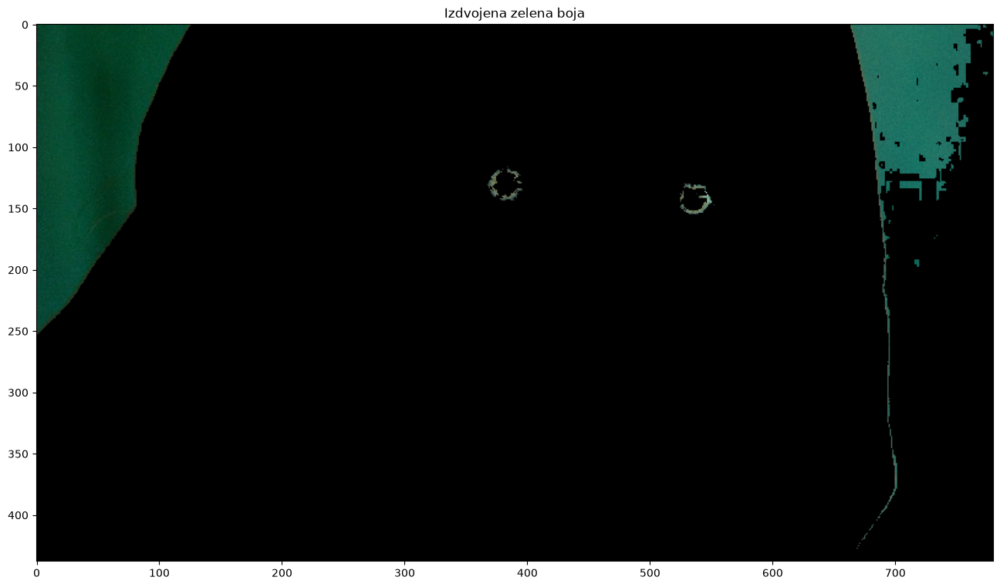

In [32]:
# opseg
lower_green = np.array([35, 40, 40])
upper_green = np.array([85, 255, 255])

# binarna maska
mask = cv2.inRange(img_hsv, lower_green, upper_green)

plt.figure()
plt.imshow(mask)
plt.title("Maska (zelena boja)")

# primena maske
img_green_only = cv2.bitwise_and(img, img, mask=mask)

plt.figure()
plt.imshow(img_green_only)
plt.title("Izdvojena zelena boja")

### Morfološke operacije

Veliki skup operacija za obradu digitalne slike, gde su te operacije zasnovane na oblicima, odnosno **strukturnim elementima**. U morfološkim operacijama, vrednost svakog piksela rezultujuće slike se zasniva na poređenju odgovarajućeg piksela na originalnoj slici sa svojom okolinom. Veličina i oblik ove okoline predstavljaju strukturni element.

In [33]:
kernel = np.ones((3, 3)) # strukturni element 3x3 blok
print(kernel)

[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]


#### Erozija

Morfološka erozija postavlja vrednost piksela rez. slike na ```(i,j)``` koordinatama na **minimalnu** vrednost svih piksela u okolini ```(i,j)``` piksela na orig. slici.

U suštini erozija umanjuje regione belih piksela, a uvećava regione crnih piksela. Često se koristi za uklanjanje šuma (u vidu sitnih regiona belih piksela).

![images/erosion.gif](images/erosion.gif)

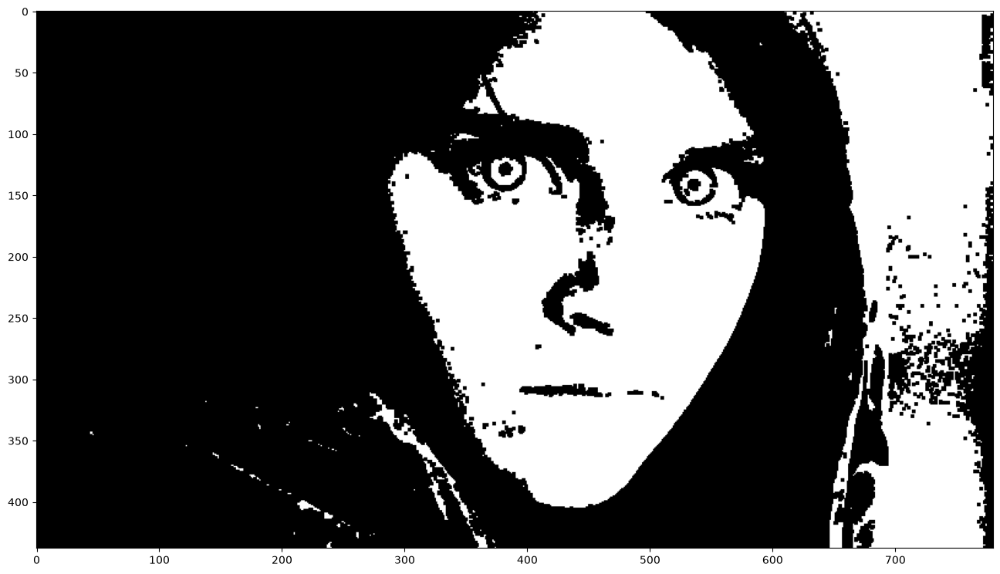

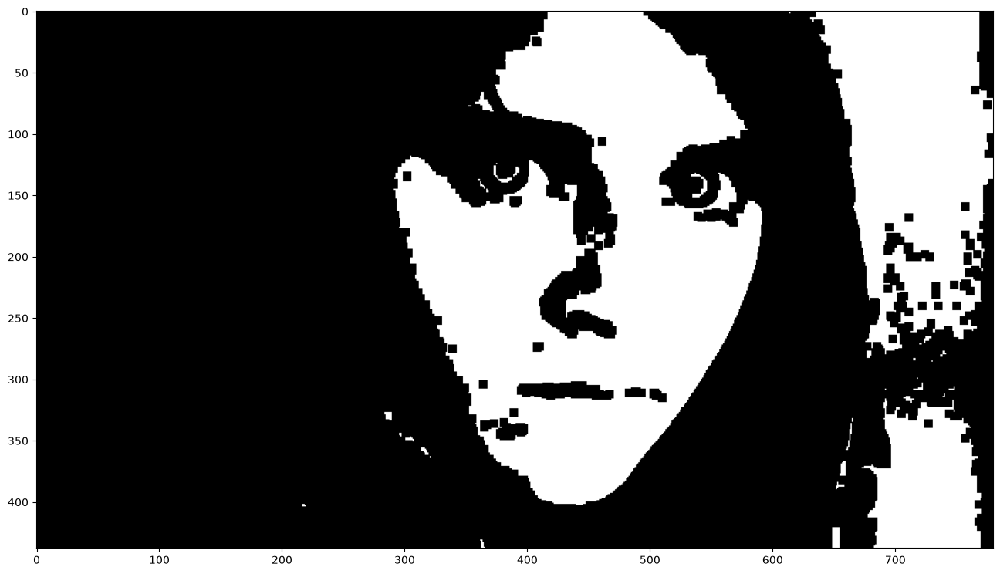

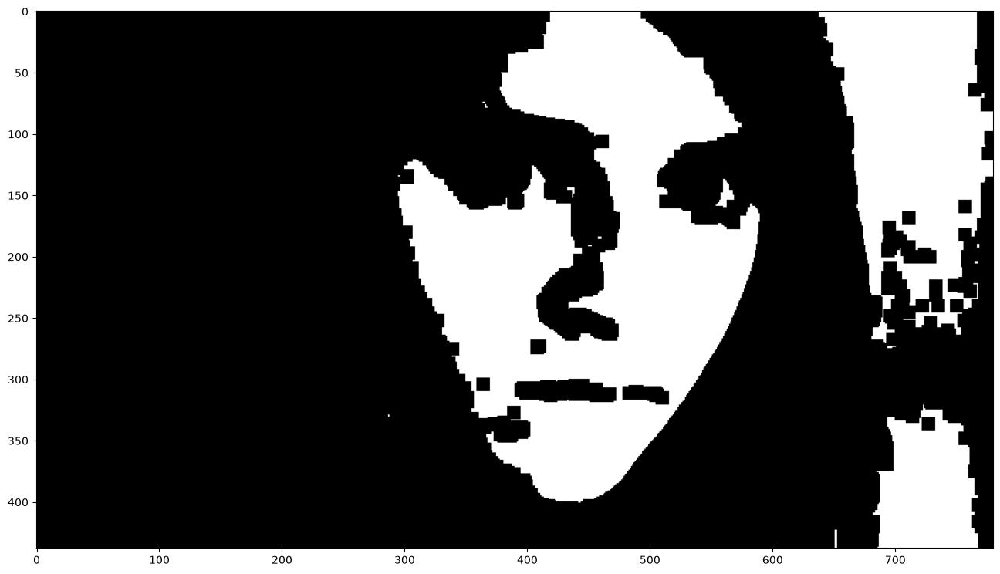

In [34]:
plt.figure()
plt.imshow(cv2.erode(image_bin, kernel, iterations=1), 'gray')
plt.figure()
plt.imshow(cv2.erode(image_bin, kernel, iterations=3), 'gray')
plt.figure()
plt.imshow(cv2.erode(image_bin, kernel, iterations=5), 'gray')

#### Dilacija

Morfološka dilacija postavlja vrednost piksela rez. slike na ```(i,j)``` koordinatama na **maksimalnu** vrednost svih piksela u okolini ```(i,j)``` piksela na orig. slici.

U suštini dilacija uvećava regione belih piksela, a umanjuje regione crnih piksela. Zgodno za izražavanje regiona od interesa.

![images/dilation.gif](images/dilation.gif)

In [35]:
# drugaciji strukturni element
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (5,5)) # MORPH_ELIPSE, MORPH_RECT
print(kernel)

[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


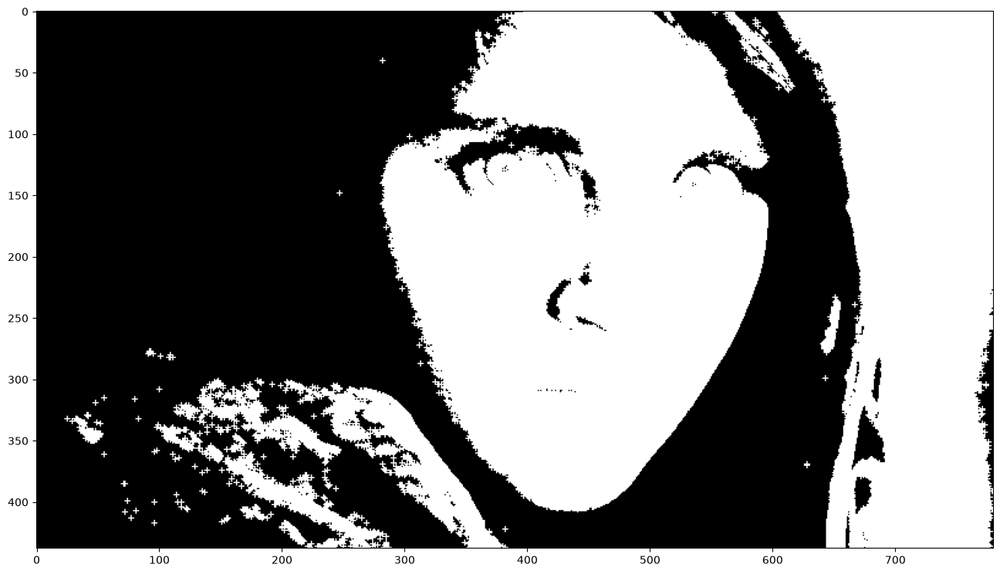

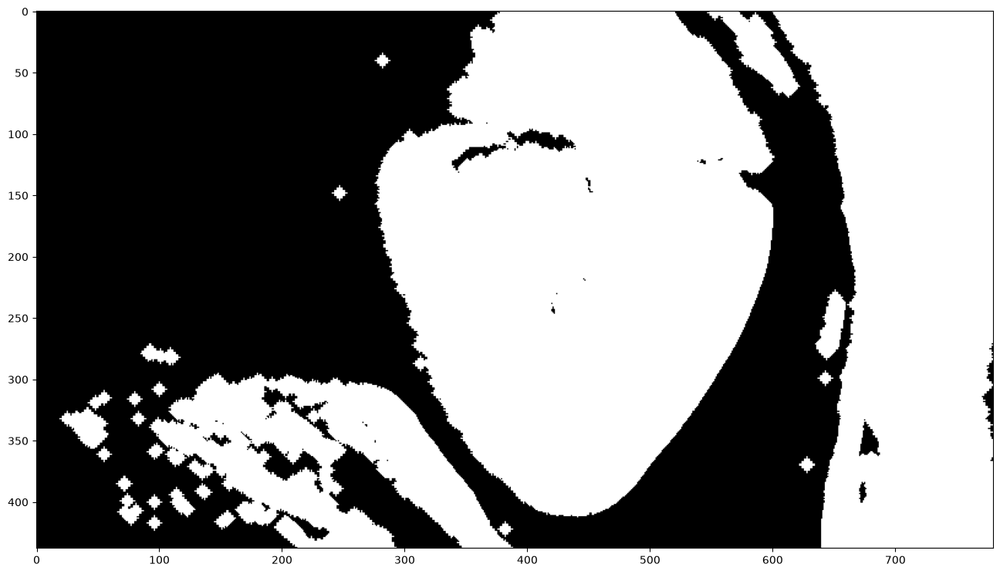

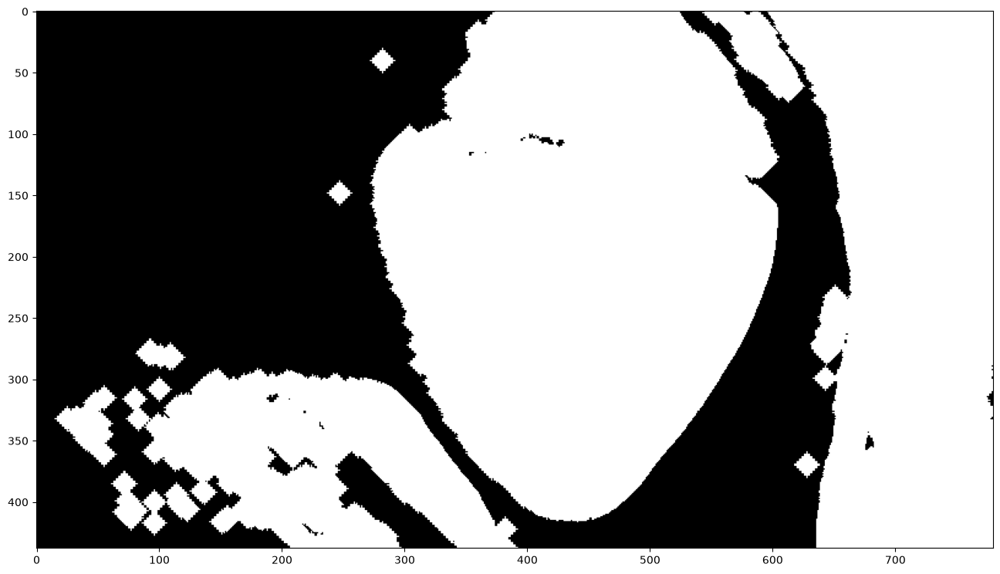

In [36]:
plt.figure()
plt.imshow(cv2.dilate(image_bin, kernel, iterations=1), 'gray')
plt.figure()
plt.imshow(cv2.dilate(image_bin, kernel, iterations=3), 'gray')
plt.figure()
plt.imshow(cv2.dilate(image_bin, kernel, iterations=5), 'gray')

#### Otvaranje i zatvaranje

**```otvaranje = erozija + dilacija```**, uklanjanje šuma erozijom i vraćanje originalnog oblika dilacijom.

**```zatvaranje = dilacija + erozija```**, zatvaranje sitnih otvora među belim pikselima

[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


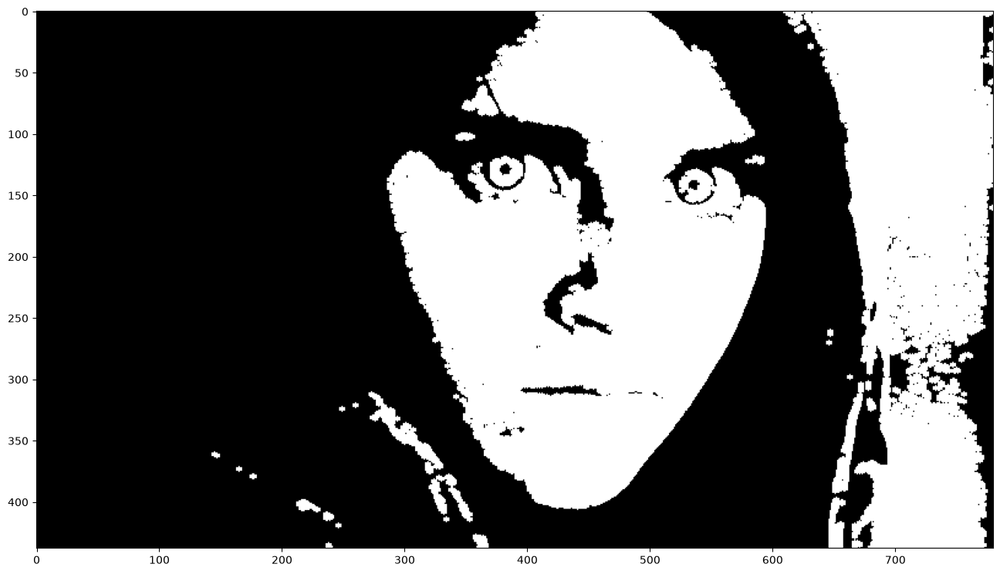

In [37]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
print(kernel)
img_open = cv2.morphologyEx(image_bin, cv2.MORPH_OPEN, kernel)
plt.imshow(img_open, 'gray')

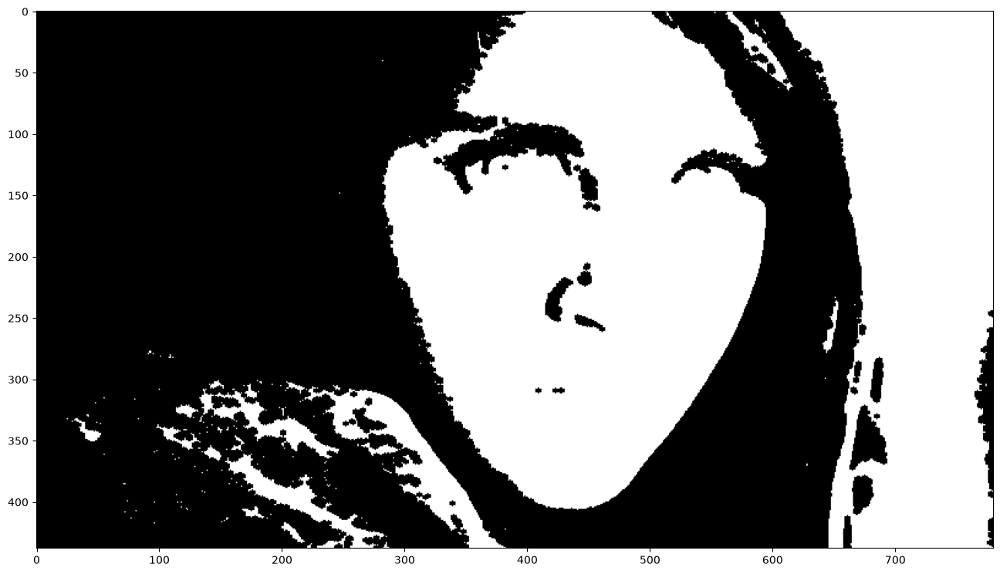

In [38]:
img_close = cv2.morphologyEx(image_bin, cv2.MORPH_CLOSE, kernel)
plt.imshow(img_close, 'gray')

OpenCV [dokumentacija](https://docs.opencv.org/5.0/py_tutorials/py_imgproc/py_morphological_ops/py_morphological_ops.html).

### Regioni i izdvajanje regiona

Najjednostavnije rečeno, region je skup međusobno povezanih belih piksela. Kada se kaže povezanih, misli se na to da se nalaze u neposrednoj okolini. Razlikuju se dve vrste povezanosti: tzv. **4-connectivity** i **8-connectivity**:

![images/48connectivity.png](images/48connectivity.png)

Postupak kojim se izdvajanju/obeležavaju regioni se naziva **connected components labelling**. Ovo ćemo primeniti na problemu izdvajanja barkoda.

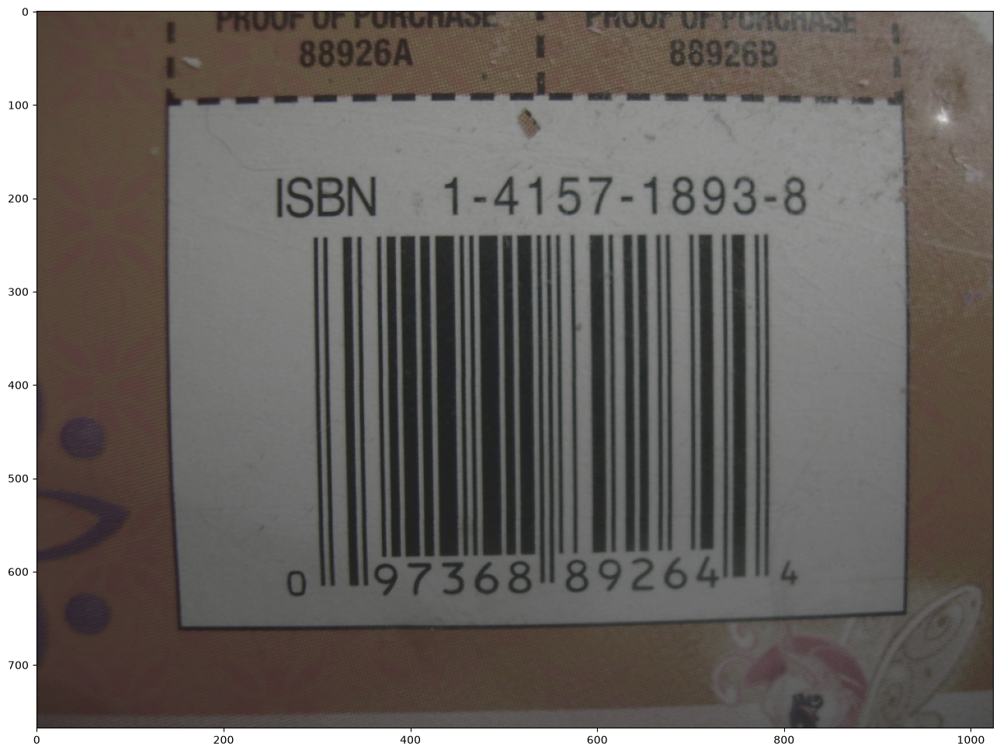

In [39]:
# ucitavanje slike i convert u RGB
img_barcode = cv2.cvtColor(cv2.imread('images/barcode.jpg'), cv2.COLOR_BGR2RGB)
plt.imshow(img_barcode)

Recimo da želimo da izdvojimo samo linije barkoda sa slike.

Za početak, uradimo neke standardne operacije, kao što je konvertovanje u grayscale i binarni threshold.

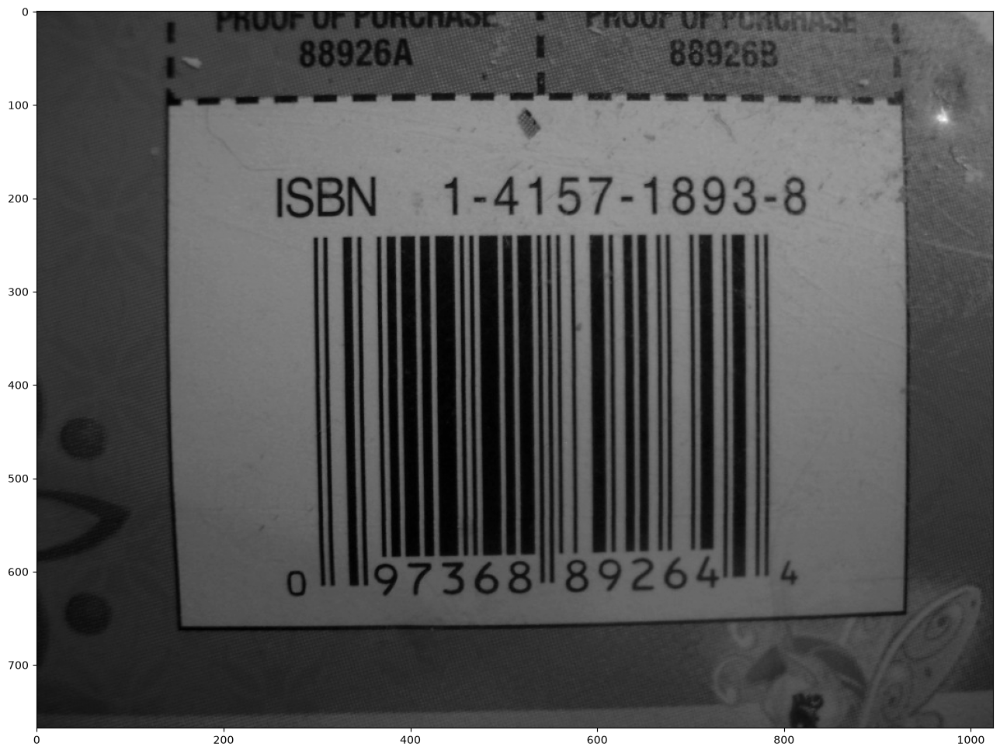

In [40]:
img_barcode_gs = cv2.cvtColor(img_barcode, cv2.COLOR_RGB2GRAY) # konvert u grayscale
plt.imshow(img_barcode_gs, 'gray')

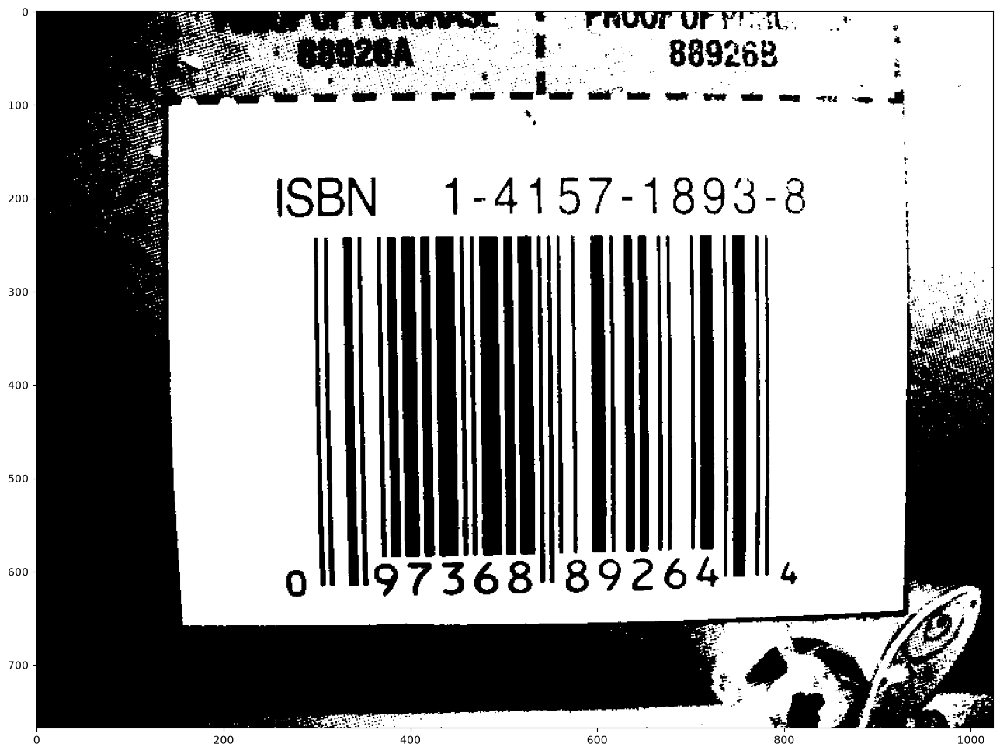

In [41]:
ret, image_barcode_bin = cv2.threshold(img_barcode_gs, 80, 255, cv2.THRESH_BINARY)
plt.imshow(image_barcode_bin, 'gray')

Pokušaćemo i sa adaptivnim thresholdom.

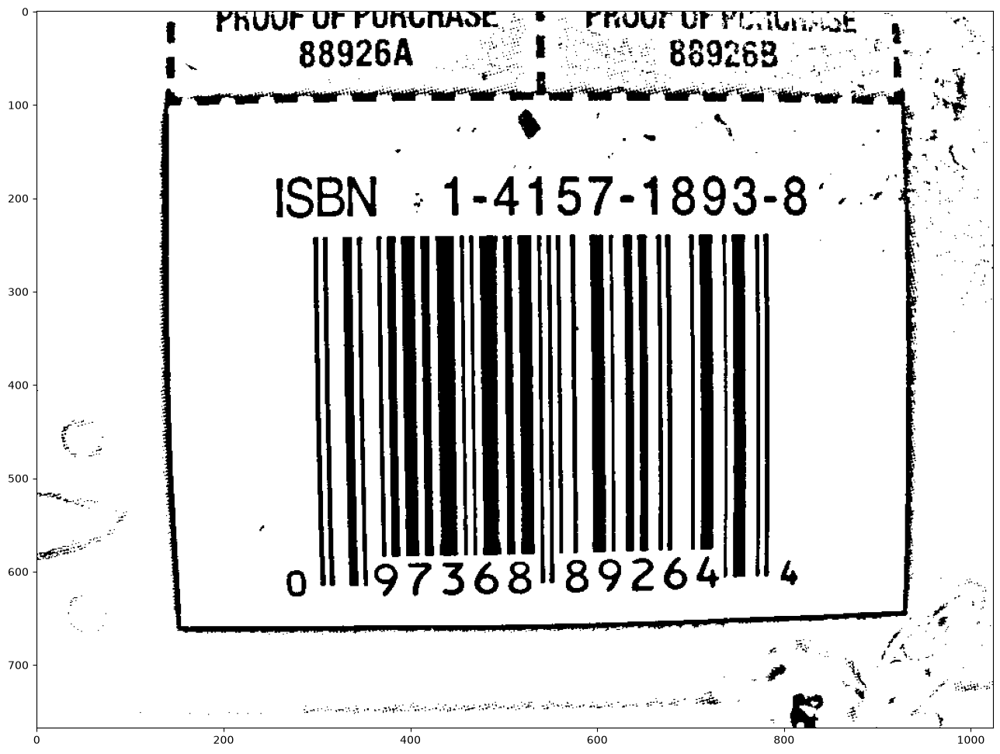

In [42]:
image_barcode_bin = cv2.adaptiveThreshold(img_barcode_gs, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 35, 10)
plt.imshow(image_barcode_bin, 'gray')

### Pronalaženje kontura/regiona

Konture, odnosno regioni na slici su grubo rečeno grupe crnih piksela. OpenCV metoda [**findContours**](https://docs.opencv.org/5.0/main_modules/imgproc_shape.html#group-imgproc-shape-1gadf1ad6a0b82947fa1fe3c3d497f260e0) pronalazi sve ove grupe crnih piksela, tj. regione. Prva povratna vrednost metode, odnosno *contours*, je lista pronađenih kontura na slici. Pored binarne slike, metodi se prosleđuju i [režim ekstrakcije kontura](https://docs.opencv.org/5.0/main_modules/imgproc_shape.html#cppv4n2cv14retrievalmodese), kao i [algoritam aproksimacije kontura](https://docs.opencv.org/5.0/main_modules/imgproc_shape.html#cppv4n2cv25contourapproximationmodese).

Ove konture je zaim moguće iscrtati metodom [**drawContours**](https://docs.opencv.org/5.0/main_modules/imgproc_draw.html#drawcontours), gde je: 
* prvi parametar slika na kojoj se iscrtavaju pronađene konture 
* drugi parametar lista kontura koje je potrebno iscrtati
* treći parametar određuje koju konturu po redosledu iscrtati (-1 znači iscrtavanje svih kontura)
* četvrti parametar je boja kojom će se obeležiti kontura
* poslednji parametar je debljina linije.

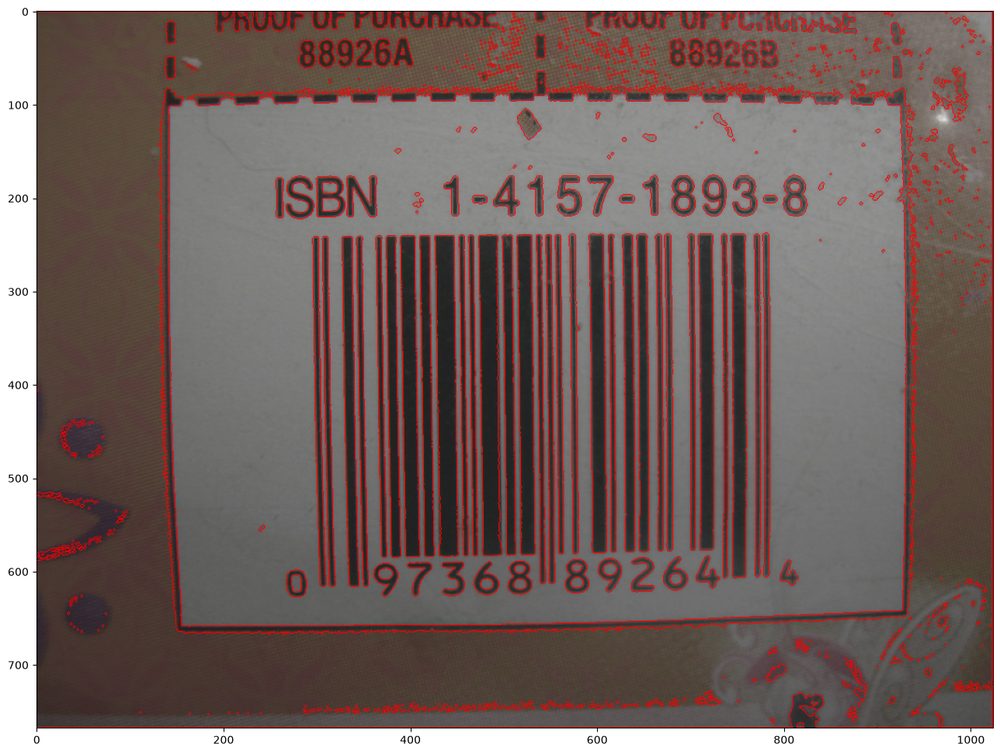

In [43]:
contours, _ = cv2.findContours(image_barcode_bin, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)

img = img_barcode.copy()
cv2.drawContours(img, contours, -1, (255, 0, 0), 1)
plt.imshow(img)

#### Osobine regiona

Svi pronađeni regioni imaju neke svoje karakteristične osobine: površina, obim, konveksni omotač, konveksnost, obuhvatajući pravougaonik, ugao...  

Ove osobine mogu biti izuzetno korisne kada je neophodno izdvojiti samo određene regione sa slike koji ispoljavaju neku osobinu.  

Za sve osobine pogledati [karakteristike](https://docs.opencv.org/5.0/py_tutorials/py_imgproc/py_contours/py_contour_features/py_contour_features.html) i [svojstva](https://docs.opencv.org/5.0/py_tutorials/py_imgproc/py_contours/py_contour_properties/py_contour_properties.html) kontura.

Izdvajamo samo bar-kod sa slike.

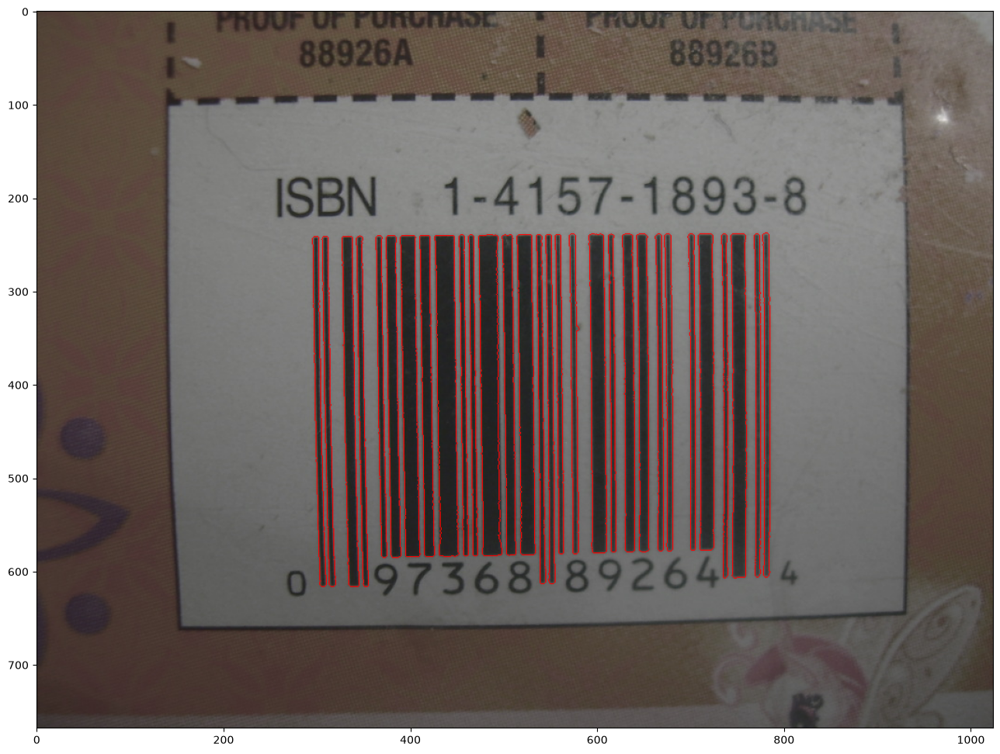

In [44]:
contours_barcode = [] # ovde ce biti samo konture koje pripadaju bar-kodu

for contour in contours: # za svaku konturu
    center, size, angle = cv2.minAreaRect(contour) # pronadji pravougaonik minimalne povrsine koji ce obuhvatiti celu konturu
    width, height = size

    if width > 3 and width < 30 and height > 300 and height < 400: # uslov da kontura pripada bar-kodu
        contours_barcode.append(contour) # ova kontura pripada bar-kodu

img = img_barcode.copy()
cv2.drawContours(img, contours_barcode, -1, (255, 0, 0), 1)
plt.imshow(img)

In [45]:
print('Ukupan broj regiona: %d' % len(contours_barcode))

Ukupan broj regiona: 30


Naravno, u ogromnom broj slučajeva odnos visine i širine neće biti dovoljan, već se moraju koristiti i ostale osobine (na primer, prethodni primer se može rešiti posmatranjem pozicije centara svih prisutnih kontura).

## Zadaci

1. Sa slike barkoda (**images/barcode.jpg**) izdvojiti samo brojeve i slova, bez linija barkoda.


2. Sa slike sa sijalicama (**images/bulbs.jpg**) prebrojati koliko ima sijalica.    


3. Na slici sa snouborderima (**images/snowboarders.jpg**) prebrojati koliko ima snoubordera.  


4. Na slici sa fudbalerima (**images/football.jpg**) izdvojiti samo one fudbalere u belim dresovima.  


5. Na slici sa crvenim krvnim zrncima (**images/bloodcells.jpg**), prebrojati koliko ima crvenih krvnih zrnaca.